# FASE 2/3 — Solo POIs · ScoreH → predictivo → contrafactuales (métricas promedio)
**Entrada: `osm_pois_checkpoint.csv`**
1. Carga del checkpoint · 2. **ScoreH** (Ranking2 editado) + **normalización 0–1** · 3. Predictivo {SVM, RF, XGBoost}
4. Contrafactuales (DiCE · MCCE · ILP)

In [ ]:
!pip install dice-ml pulp xgboost scikit-learn -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 61.2 MB/s eta 0:00:00


In [ ]:
import numpy as np, pandas as pd, warnings, json
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix)

# ─────────── CONFIG ───────────
RUTA_LONG    = 'osm_distancias_long_checkpoint.csv'  # formato largo: id_proyecto, categoria, dist_m
RUTA_PROC    = 'osm_distancias_procesados.csv'       # opcional: universo completo (incluye 0 POIs)
THRESHOLD    = 0.60      # umbral ScoreHNorm para FlgHabita
RANDOM_STATE = 42
TEST_SIZE    = 0.20
BUDGET       = 15        # presupuesto ILP
N_MCCE       = 3000      # muestras Monte-Carlo por hogar
N_CRITICOS   = None      # nº de hogares críticos a evaluar (None = todos; baja p.ej. a 60 si vas con prisa)

POI_COLS = ['Bus','Primaria','Universitaria','Hospitales',
            'Alimentacion','Tienda','EspaciosPublicos','Farmacias']
POIS_MODIFICABLES = ['Bus','Primaria','Alimentacion','Tienda','EspaciosPublicos','Farmacias']
print('Config lista.')

Config lista.


## 1 · Del formato largo a conteos por proyecto

El archivo viene en **formato largo** (`id_proyecto, categoria, dist_m`, una fila por POI). Se cuenta el nº de filas por
`id_proyecto × categoria` para obtener los **conteos** por categoría (formato ancho). Un proyecto sin POIs en una
categoría queda en 0; con `osm_distancias_procesados.csv` se incluyen además los proyectos con 0 POIs en todas.

In [ ]:
import os
long = pd.read_csv(RUTA_LONG)
long.columns = [c.strip().lower() for c in long.columns]
long = long[['id_proyecto','categoria','dist_m']]

# ── CONTEO: nº de filas por proyecto y categoría ──
conteos = (long.groupby(['id_proyecto','categoria']).size()
                .unstack('categoria', fill_value=0))
for c in POI_COLS:                       # asegurar las 8 columnas
    if c not in conteos.columns: conteos[c] = 0
conteos = conteos[POI_COLS]

# universo completo (proyectos con 0 POIs en todas las categorías)
if os.path.exists(RUTA_PROC):
    proc = pd.read_csv(RUTA_PROC); proc.columns=[c.strip().lower() for c in proc.columns]
    conteos = conteos.reindex(sorted(proc['id_proyecto'].unique()), fill_value=0)
    print('Universo desde procesados:', len(conteos))

df = conteos.reset_index()
df[POI_COLS] = df[POI_COLS].astype(int)
print('Proyectos con conteos:', len(df), '| POIs:', POI_COLS)
df[POI_COLS].describe().T[['mean','max']]


Proyectos con conteos: 1822 | POIs: ['Bus', 'Primaria', 'Universitaria', 'Hospitales', 'Alimentacion', 'Tienda', 'EspaciosPublicos', 'Farmacias']


,mean,max
categoria,,
Bus,13.834797,83.0
Primaria,35.460483,94.0
Universitaria,5.151482,32.0
Hospitales,7.003842,25.0
Alimentacion,51.558727,397.0
Tienda,11.653128,73.0
EspaciosPublicos,47.818332,106.0
Farmacias,17.974204,60.0


## 2 · ScoreH (Ranking2 editado) y normalización 0–1

Prioridad **Salud (0.25) + Alimentación (0.22) + Educación (0.20)**. La normalización 0–1 se hace con Min-Max
sobre `ScoreH` (guardando `min`/`max` para poder revertir o aplicar a nuevos datos).

In [ ]:
diccPeso = {"SALUD":0.25,"ALIMENTACION":0.22,"EDUCACION":0.20,
            "TRANSPORTE":0.15,"COMERCIO":0.10,"RECREACION":0.08}
diccRelevancia = {"Bus":1,"Primaria":2,"Universitaria":1,"Hospitales":3,
                  "Alimentacion":2,"Tienda":2,"EspaciosPublicos":3,"Farmacias":1}
diccSubCategorias = {'Bus':"TRANSPORTE",'Primaria':"EDUCACION",'Universitaria':"EDUCACION",
                     'Hospitales':"SALUD",'Farmacias':"SALUD",'Alimentacion':"ALIMENTACION",
                     'Tienda':"COMERCIO",'EspaciosPublicos':"RECREACION"}

def calcular_scoreH(frame, poi_cols=POI_COLS):
    counts = frame[poi_cols].astype(float).fillna(0)
    rel = pd.DataFrame({c: np.where(counts[c]>0, diccRelevancia.get(c,0), 0.0)
                        for c in poi_cols}, index=counts.index)
    Z = RobustScaler().fit_transform(counts.values)
    N = pd.DataFrame(1/(1+np.exp(-Z)), index=counts.index, columns=poi_cols)
    s = pd.Series(0.0, index=counts.index)
    for c in poi_cols:
        s += rel[c]*N[c]*diccPeso[diccSubCategorias[c]]
    return s

df['ScoreH'] = calcular_scoreH(df)

# ── Normalización 0–1 (Min-Max) ──
score_min, score_max = float(df['ScoreH'].min()), float(df['ScoreH'].max())
if score_max > score_min:
    df['ScoreHNorm'] = (df['ScoreH'] - score_min) / (score_max - score_min)
else:
    df['ScoreHNorm'] = 0.0
df['FlgHabita'] = (df['ScoreHNorm'] >= THRESHOLD).astype(int)

print(f'ScoreH     : min={score_min:.4f}  max={score_max:.4f}')
print(f'ScoreHNorm : min={df.ScoreHNorm.min():.2f}  max={df.ScoreHNorm.max():.2f}  (debe ser 0 y 1)')
vc = df['FlgHabita'].value_counts()
print(f'FlgHabita  : Habitable(1)={vc.get(1,0)}  ·  No habitable(0)={vc.get(0,0)}')


ScoreH     : min=0.0249  max=2.1420
ScoreHNorm : min=0.00  max=1.00  (debe ser 0 y 1)
FlgHabita  : Habitable(1)=945  ·  No habitable(0)=877


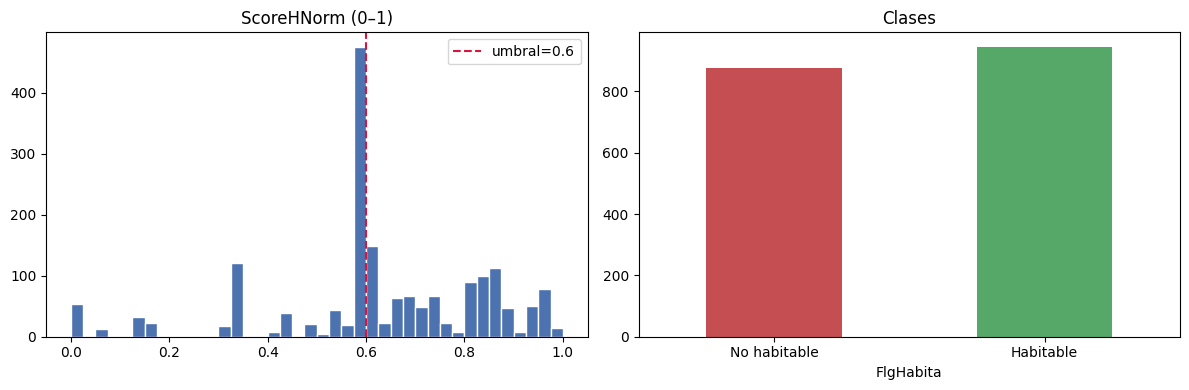

In [ ]:
# Distribución del score
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].hist(df['ScoreHNorm'], bins=40, color='#4C72B0', edgecolor='white')
ax[0].axvline(THRESHOLD, color='crimson', ls='--', label=f'umbral={THRESHOLD}')
ax[0].set_title('ScoreHNorm (0–1)'); ax[0].legend()
df['FlgHabita'].value_counts().sort_index().plot.bar(ax=ax[1], color=['#C44E52','#55A868'])
ax[1].set_xticklabels(['No habitable','Habitable'], rotation=0); ax[1].set_title('Clases')
plt.tight_layout(); plt.show()


## 3 · Predictivo — {SVM, Random Forest, XGBoost} → retener el mejor

In [ ]:
feature_cols = list(POI_COLS)   # SOLO conteos de POIs
X = df[feature_cols].copy(); y = df['FlgHabita'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

modelos = {
    'SVM': Pipeline([('sc',StandardScaler()),
                     ('m',SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=RANDOM_STATE))]),
    'RandomForest': RandomForestClassifier(n_estimators=400, class_weight='balanced',
                     random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.1, subsample=0.9,
                     eval_metric='logloss', random_state=RANDOM_STATE),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy','precision','recall','f1']
filas=[]; fitted={}
for nombre, mdl in modelos.items():
    # métricas promedio por validación cruzada (5-fold) sobre train
    cvr = cross_validate(mdl, X_train, y_train, cv=cv, scoring=scoring)
    mdl.fit(X_train, y_train); fitted[nombre]=mdl
    p = mdl.predict(X_test)
    filas.append({'Modelo':nombre,
        'Acc_cv':cvr['test_accuracy'].mean(), 'Prec_cv':cvr['test_precision'].mean(),
        'Rec_cv':cvr['test_recall'].mean(),   'F1_cv':cvr['test_f1'].mean(),
        'Acc_test':accuracy_score(y_test,p),  'Prec_test':precision_score(y_test,p,zero_division=0),
        'Rec_test':recall_score(y_test,p,zero_division=0), 'F1_test':f1_score(y_test,p,zero_division=0)})
resultados = pd.DataFrame(filas).sort_values('F1_test', ascending=False).reset_index(drop=True)
print(resultados.round(4).to_string(index=False))
resultados


      Modelo  Acc_cv  Prec_cv  Rec_cv  F1_cv  Acc_test  Prec_test  Rec_test  F1_test
         SVM  0.9931   0.9948  0.9921 0.9934    0.9973     0.9947       1.0   0.9974
RandomForest  0.9979   0.9961  1.0000 0.9980    0.9973     0.9947       1.0   0.9974
     XGBoost  0.9979   0.9961  1.0000 0.9980    0.9945     0.9895       1.0   0.9947


,Modelo,Acc_cv,Prec_cv,Rec_cv,F1_cv,Acc_test,Prec_test,Rec_test,F1_test
0,SVM,0.993139,0.994754,0.992062,0.993368,0.997260,0.994737,1.0,0.997361
1,RandomForest,0.997940,0.996078,1.000000,0.998028,0.997260,0.994737,1.0,0.997361
2,XGBoost,0.997940,0.996078,1.000000,0.998028,0.994521,0.989529,1.0,0.994737


In [ ]:
mejor_nombre = resultados.iloc[0]['Modelo']
best_model = fitted[mejor_nombre]
print(f'🏆 Mejor modelo: {mejor_nombre}')
pred = best_model.predict(X_test)
print('  Accuracy :', round(accuracy_score(y_test,pred),4))
print('  Precision:', round(precision_score(y_test,pred,zero_division=0),4))
print('  Recall   :', round(recall_score(y_test,pred,zero_division=0),4))
print('  F1       :', round(f1_score(y_test,pred,zero_division=0),4))
print('\n', classification_report(y_test, pred, target_names=['No habitable','Habitable']))


🏆 Mejor modelo: SVM
  Accuracy : 0.9973
  Precision: 0.9947
  Recall   : 1.0
  F1       : 0.9974

               precision    recall  f1-score   support

No habitable       1.00      0.99      1.00       176
   Habitable       0.99      1.00      1.00       189

    accuracy                           1.00       365
   macro avg       1.00      1.00      1.00       365
weighted avg       1.00      1.00      1.00       365



## 4 · Hogares críticos, costos, restricciones y métricas de un contrafactual

In [ ]:
BANDA_INF, BANDA_SUP = 0.40, 0.60
sn = df.loc[X_test.index, "ScoreHNorm"]              # score de habitabilidad de cada hogar de test
X_test_s = X_test.copy()
X_test_s["ScoreHNorm"] = sn
X_test_s["proba"] = best_model.predict_proba(X_test)[:,1]
critical_homes = X_test_s[(X_test_s["ScoreHNorm"] > BANDA_INF) &
                          (X_test_s["ScoreHNorm"] < BANDA_SUP)].copy()
if N_CRITICOS: critical_homes = critical_homes.iloc[:N_CRITICOS]
print(f"Hogares con ScoreHNorm en ({BANDA_INF},{BANDA_SUP}): {len(critical_homes)}")

# Alternativa: si quieres la banda sobre la probabilidad del modelo, usa:
# critical_homes = X_test_s[(X_test_s["proba"]>0.4) & (X_test_s["proba"]<0.6)].copy()
cost_dict = {'Bus':1,'Primaria':50,'Universitaria':300,'Hospitales':50,
             'Farmacias':30,'Tienda':10,'Alimentacion':20,'EspaciosPublicos':30}
delta = 3
constraints = {poi: int(df[poi].max())+delta for poi in POIS_MODIFICABLES}

def compute_sparsity(x, cf): return int(np.sum(x.values != cf.values))
def compute_l1(x, cf):       return float(np.sum(np.abs(cf.values - x.values)))
def compute_cost(x, cf):
    t=0.0
    for col in POI_COLS:
        d=cf[col]-x[col]
        if d>0: t+=d*cost_dict.get(col,1)
    return t
# --- proximity necesita la MAD por feature (dispersión robusta) ---
_mad = (X[POI_COLS] - X[POI_COLS].median()).abs().median().replace(0, 1.0)
def compute_proximity(x, cf):
    # L1 normalizada por MAD; MENOR = más próximo (más realista)
    return float(np.mean([abs(cf[c]-x[c])/_mad[c] for c in POI_COLS]))

def compute_metrics(orig, cf):
    old = best_model.predict_proba(pd.DataFrame([orig]))[0,1]
    new = best_model.predict_proba(pd.DataFrame([cf]))[0,1]
    m = {"OldScore":float(old),"DeltaScore":float(new-old),"NewScore":float(new),
         "Flip":int(new>=THRESHOLD),"Validity":int(new>=THRESHOLD),
         "Sparsity":compute_sparsity(orig,cf),"L1":compute_l1(orig,cf),
         "Proximity":compute_proximity(orig,cf),"Cost":compute_cost(orig,cf)}
    for c in POI_COLS:                       # cuántos POIs se añaden por categoría
        d = cf[c]-orig[c]
        m[f"+{c}"] = int(round(d)) if d>0 else 0
    return m


Hogares con ScoreHNorm en (0.4,0.6): 130


## 5 · Definición de los tres métodos contrafactuales

In [ ]:
import dice_ml
from pulp import LpProblem, LpMaximize, LpVariable, lpSum, PULP_CBC_CMD

def build_dice_explainer(df_full, model, feature_cols):
    d2 = df_full[feature_cols].copy(); d2["FlgHabita"]=df_full["FlgHabita"].values
    data = dice_ml.Data(dataframe=d2, continuous_features=list(feature_cols), outcome_name="FlgHabita")
    return dice_ml.Dice(data, dice_ml.Model(model=model, backend="sklearn"), method="genetic")

def run_dice(explainer, query, total_CFs=5):
    orig = query.iloc[0]
    permitted = {p:[int(orig[p]), int(orig[p])+constraints[p]] for p in POIS_MODIFICABLES}
    cfo = explainer.generate_counterfactuals(query, total_CFs=total_CFs, desired_class=1,
            features_to_vary=POIS_MODIFICABLES, permitted_range=permitted)
    return pd.DataFrame([compute_metrics(orig, r[query.columns]) for _,r in
                         cfo.cf_examples_list[0].final_cfs_df.iterrows()])

def run_mcce(x, model, n_samples=N_MCCE, top_k=5):
    cands=[]
    for _ in range(n_samples):
        c=x.copy()
        for poi,mx in constraints.items(): c[poi]+=np.random.randint(0,mx+1)
        cands.append((model.predict_proba(pd.DataFrame([c]))[0,1], c))
    cands.sort(key=lambda t:t[0], reverse=True)
    return pd.DataFrame([compute_metrics(x, cf) for _,cf in cands[:top_k]])

def run_ilp(x, model, budget=BUDGET):
    prob=LpProblem("ILP", LpMaximize)
    v={p:LpVariable(p, lowBound=0, upBound=mx, cat="Integer") for p,mx in constraints.items()}
    prob += lpSum(v.values()); prob += lpSum(cost_dict.get(p,1)*v[p] for p in v) <= budget
    prob.solve(PULP_CBC_CMD(msg=0))
    cf=x.copy()
    for p,var in v.items(): cf[p]+=int(var.varValue or 0)
    return pd.DataFrame([compute_metrics(x, cf)])

dice_explainer = build_dice_explainer(df, best_model, feature_cols)
print('Métodos listos.')


Métodos listos.


## 6 · Ejecutar los 3 métodos sobre TODOS los hogares críticos

Para cada hogar se toma el **mejor contrafactual** (mayor `NewScore`) y se registran sus métricas; luego se promedian.

In [ ]:
def resumen_metodo(res):
    if res is None or len(res)==0: return None
    best = res.sort_values("NewScore", ascending=False).iloc[0]     # mejor contrafactual del hogar
    out = {k: best[k] for k in ["OldScore","DeltaScore","NewScore","Flip",
                                "Sparsity","L1","Proximity","Cost"]}
    out["Validity"] = float(res["Flip"].mean())    # fracción de CFs generados que son válidos
    for c in POI_COLS: out[f"+{c}"] = int(best.get(f"+{c}",0))
    return out

C = critical_homes[feature_cols].copy()
regs = []
for i in range(len(C)):
    q = C.iloc[[i]]; x = C.iloc[i]
    try:    d = resumen_metodo(run_dice(dice_explainer, q, total_CFs=5))
    except Exception: d = None
    if d: regs.append({"metodo":"DiCE", **d})
    m = resumen_metodo(run_mcce(x, best_model, n_samples=N_MCCE, top_k=5))
    if m: regs.append({"metodo":"MCCE", **m})
    l = resumen_metodo(run_ilp(x, best_model, budget=BUDGET))
    if l: regs.append({"metodo":"ILP", **l})
    if (i+1) % 20 == 0: print(f"  {i+1}/{len(C)} hogares")
per_home = pd.DataFrame(regs)
print("Filas (hogar×método):", len(per_home))
per_home.head()

100%|██████████| 1/1 [00:00<00:00,  5.18it/s]


  20/130 hogares


100%|██████████| 1/1 [00:00<00:00,  6.13it/s]


  40/130 hogares


100%|██████████| 1/1 [00:00<00:00,  5.32it/s]


  60/130 hogares


... (5 outputs left out)

  120/130 hogares


100%|██████████| 1/1 [00:00<00:00,  3.76it/s]


Filas (hogar×método): 390


,metodo,OldScore,DeltaScore,NewScore,Flip,Sparsity,L1,Proximity,Cost,Validity,+Bus,+Primaria,+Universitaria,+Hospitales,+Alimentacion,+Tienda,+EspaciosPublicos,+Farmacias
0,DiCE,0.006301,0.988097,0.994398,1.0,1.0,240.0,1.200000,4800.0,0.8,0,0,0,0,240,0,0,0
1,MCCE,0.006301,0.993699,1.000000,1.0,6.0,84.0,1.795777,1314.0,1.0,34,11,0,0,18,13,2,6
2,ILP,0.006301,0.970333,0.976634,1.0,1.0,15.0,0.468750,15.0,1.0,15,0,0,0,0,0,0,0
3,DiCE,0.006301,0.993699,1.000000,1.0,1.0,85.0,0.425000,1700.0,1.0,0,0,0,0,85,0,0,0
4,MCCE,0.006301,0.993699,1.000000,1.0,5.0,117.0,1.704643,2338.0,1.0,18,11,0,0,57,15,0,16


In [ ]:
metricas = ["Validity","DeltaScore","NewScore","Flip","Sparsity","Proximity","L1","Cost"]
resumen = (per_home.groupby("metodo")[metricas].mean()
           .reindex(["DiCE","MCCE","ILP"]).rename(columns={"Flip":"FlipRate"}))
resumen["FlipRate"] *= 100; resumen["Validity"] *= 100      # a %
print("MÉTRICAS PROMEDIO POR MÉTODO:"); print(resumen.round(3).to_string())

inc_cols = [f"+{c}" for c in POI_COLS]
incrementos = (per_home.groupby("metodo")[inc_cols].mean()
               .reindex(["DiCE","MCCE","ILP"]).round(2))
print("\nINCREMENTO MEDIO DE POIs POR CATEGORÍA (¿realista o exagerado?):")
print(incrementos.to_string())

MÉTRICAS PROMEDIO POR MÉTODO:
        Validity  DeltaScore  NewScore  FlipRate  Sparsity  Proximity       L1      Cost
metodo                                                                                  
DiCE      89.385       0.983     0.997   100.000     1.054      0.873  120.669  2598.077
MCCE     100.000       0.986     1.000   100.000     5.769      1.689  136.315  3011.977
ILP       93.846       0.923     0.937    93.846     1.000      0.469   15.000    15.000

INCREMENTO MEDIO DE POIs POR CATEGORÍA (¿realista o exagerado?):
         +Bus  +Primaria  +Universitaria  +Hospitales  +Alimentacion  +Tienda  +EspaciosPublicos  +Farmacias
metodo                                                                                                      
DiCE     0.08       2.10             0.0          0.0         100.85     2.66               0.51       14.47
MCCE    13.13      16.48             0.0          0.0          72.65    14.99               8.99       10.06
ILP     15.00       0.0

In [ ]:
def mostrar_prescripcion(i=0, metodo="ILP"):
    x = critical_homes[feature_cols].iloc[i]
    if   metodo=="DiCE": res = run_dice(dice_explainer, critical_homes[feature_cols].iloc[[i]], total_CFs=5)
    elif metodo=="MCCE": res = run_mcce(x, best_model, n_samples=N_MCCE, top_k=5)
    else:                res = run_ilp(x, best_model, budget=BUDGET)
    b = res.sort_values("NewScore", ascending=False).iloc[0]
    print(f"[{metodo}] hogar {i} | Old={b.OldScore:.2f} → New={b.NewScore:.2f} | Flip={int(b.Flip)} | Cost={b.Cost:.0f}")
    print("  POIs a añadir:", {p:int(b[f'+{p}']) for p in POI_COLS if b[f'+{p}']>0})

mostrar_prescripcion(0, "ILP"); mostrar_prescripcion(0, "MCCE"); mostrar_prescripcion(0, "DiCE")

[ILP] hogar 0 | Old=0.01 → New=0.98 | Flip=1 | Cost=15
  POIs a añadir: {'Bus': 15}
[MCCE] hogar 0 | Old=0.01 → New=1.00 | Flip=1 | Cost=2693
  POIs a añadir: {'Bus': 3, 'Primaria': 13, 'Alimentacion': 60, 'Tienda': 18, 'EspaciosPublicos': 2, 'Farmacias': 20}


100%|██████████| 1/1 [00:00<00:00,  5.54it/s]

[DiCE] hogar 0 | Old=0.01 → New=1.00 | Flip=1 | Cost=1420


  POIs a añadir: {'Alimentacion': 71}


In [ ]:
def mejor_cf(res):
    if res is None or len(res)==0: return None
    return res.sort_values('NewScore', ascending=False).iloc[0]

C = critical_homes.drop(columns=['proba'])
regs = []
for i in range(len(C)):
    q = C.iloc[[i]]; x = C.iloc[i]
    # DiCE
    try:    b = mejor_cf(run_dice(dice_explainer, q, total_CFs=5))
    except Exception: b = None
    if b is not None: regs.append({'metodo':'DiCE', **{k:b[k] for k in ['DeltaScore','NewScore','Flip','Sparsity','L1','Cost']}})
    # MCCE
    b = mejor_cf(run_mcce(x, best_model, n_samples=N_MCCE, top_k=5))
    if b is not None: regs.append({'metodo':'MCCE', **{k:b[k] for k in ['DeltaScore','NewScore','Flip','Sparsity','L1','Cost']}})
    # ILP
    b = mejor_cf(run_ilp(x, best_model, budget=BUDGET))
    if b is not None: regs.append({'metodo':'ILP', **{k:b[k] for k in ['DeltaScore','NewScore','Flip','Sparsity','L1','Cost']}})
    if (i+1) % 20 == 0: print(f'  {i+1}/{len(C)} hogares procesados')

per_home = pd.DataFrame(regs)
print('Filas (hogar×método):', len(per_home))
per_home.head()


100%|██████████| 1/1 [00:00<00:00,  3.16it/s]


  20/175 hogares procesados


100%|██████████| 1/1 [00:00<00:00,  5.55it/s]


  40/175 hogares procesados


100%|██████████| 1/1 [00:00<00:00,  5.33it/s]


  60/175 hogares procesados


... (9 outputs left out)

  160/175 hogares procesados


100%|██████████| 1/1 [00:00<00:00,  3.09it/s]


Filas (hogar×método): 525


,metodo,DeltaScore,NewScore,Flip,Sparsity,L1,Cost
0,DiCE,0.989364,0.995665,1.0,1.0,38.0,1140.0
1,MCCE,0.993699,1.000000,1.0,6.0,79.0,1377.0
2,ILP,0.970333,0.976634,1.0,1.0,15.0,15.0
3,DiCE,0.986408,0.991258,1.0,1.0,218.0,4360.0
4,MCCE,0.995150,1.000000,1.0,6.0,217.0,5195.0


## 7 · Métricas importantes en promedio (por método)

In [ ]:
resumen = (per_home.groupby('metodo')
           .agg(DeltaScore=('DeltaScore','mean'),
                NewScore=('NewScore','mean'),
                FlipRate=('Flip','mean'),          # % de hogares que logran volverse habitables
                Sparsity=('Sparsity','mean'),      # nº medio de POIs modificados
                L1=('L1','mean'),
                Cost=('Cost','mean'),
                n=('Flip','size'))
           .reindex(['DiCE','MCCE','ILP']))
resumen['FlipRate'] = (resumen['FlipRate']*100).round(1)   # a %
print('MÉTRICAS PROMEDIO POR MÉTODO:')
print(resumen.round(3).to_string())
resumen


MÉTRICAS PROMEDIO POR MÉTODO:
        DeltaScore  NewScore  FlipRate  Sparsity       L1      Cost    n
metodo                                                                  
DiCE         0.990     0.996     100.0     1.143  143.669  3129.846  175
MCCE         0.993     1.000     100.0     5.811  158.149  3627.743  175
ILP          0.705     0.712      70.3     1.000   15.000    15.000  175


,DeltaScore,NewScore,FlipRate,Sparsity,L1,Cost,n
metodo,,,,,,,
DiCE,0.989739,0.996398,100.0,1.142857,143.668571,3129.845714,175
MCCE,0.993340,1.000000,100.0,5.811429,158.148571,3627.742857,175
ILP,0.705258,0.711918,70.3,1.000000,15.000000,15.000000,175


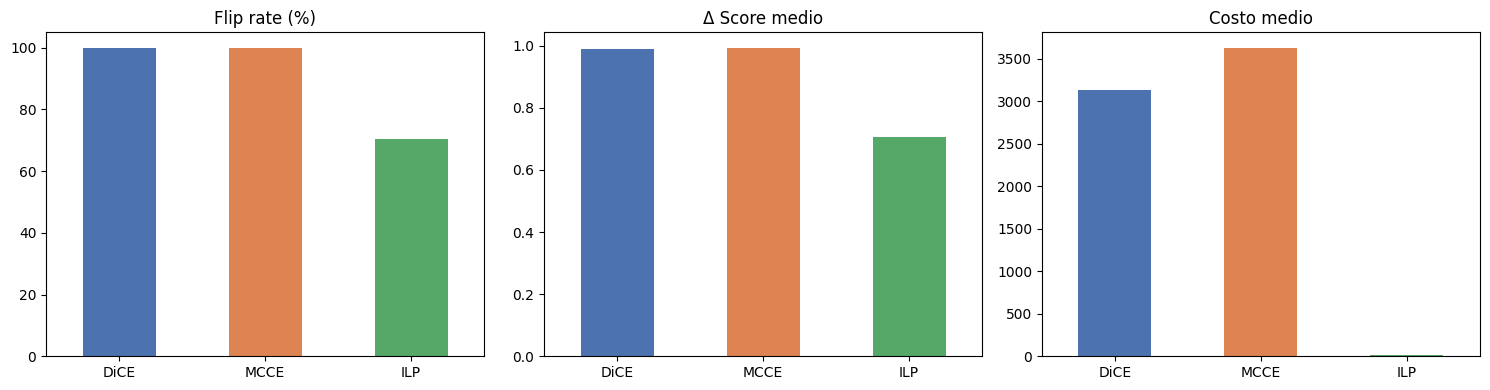

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,3, figsize=(15,4))
resumen['FlipRate'].plot.bar(ax=ax[0], color=['#4C72B0','#DD8452','#55A868']); ax[0].set_title('Flip rate (%)')
resumen['DeltaScore'].plot.bar(ax=ax[1], color=['#4C72B0','#DD8452','#55A868']); ax[1].set_title('Δ Score medio')
resumen['Cost'].plot.bar(ax=ax[2], color=['#4C72B0','#DD8452','#55A868']); ax[2].set_title('Costo medio')
for a in ax: a.tick_params(axis='x', rotation=0); a.set_xlabel('')
plt.tight_layout(); plt.show()


## 8 · Export

In [ ]:
import joblib
joblib.dump({'modelo':best_model,'nombre':mejor_nombre,'features':feature_cols,
             'threshold':THRESHOLD,'score_min':score_min,'score_max':score_max,
             'constraints':constraints,'cost_dict':cost_dict}, 'modelo_solo_pois.joblib')
df.to_csv('dataset_scoreH_pois.csv', index=False, encoding='utf-8-sig')
resultados.to_csv('comparacion_modelos_predictivos.csv', index=False, encoding='utf-8-sig')
per_home.to_csv('contrafactuales_por_hogar.csv', index=False, encoding='utf-8-sig')
resumen.to_csv('metricas_promedio_metodos.csv', encoding='utf-8-sig')
print('✅ Exportado: modelo_solo_pois.joblib, dataset_scoreH_pois.csv,')
print('   comparacion_modelos_predictivos.csv, contrafactuales_por_hogar.csv, metricas_promedio_metodos.csv')


✅ Exportado: modelo_solo_pois.joblib, dataset_scoreH_pois.csv,
   comparacion_modelos_predictivos.csv, contrafactuales_por_hogar.csv, metricas_promedio_metodos.csv


---
### Notas
- **Entrada única:** `osm_distancias_long_checkpoint.csv` (formato largo). Se pivotea a conteos contando filas por `id_proyecto × categoria`. Nada de demografía ni infraestructura; features = solo los 8 conteos de POI.
- **Normalización 0–1:** Min-Max sobre `ScoreH`; se guardan `score_min`/`score_max` en el `.joblib` para aplicarla a datos nuevos sin recalcular el rango.
- **Predictivo:** {SVM, RandomForest, XGBoost} con accuracy/precision/recall/F1 (promedio por validación cruzada 5-fold **y** en test); se retiene el de mayor F1.
- **Contrafactuales:** por hogar se toma el mejor CF (mayor NewScore); las métricas se promedian por método. `FlipRate` = % de hogares que logran volverse habitables. Baja `N_CRITICOS`/`N_MCCE` si necesitas correr más rápido.
- **Nota:** al usar solo POIs, `FlgHabita` es función de esos mismos conteos, por lo que los modelos separan muy bien; el valor está en los contrafactuales (qué POIs añadir para volver habitable cada proyecto).
